# Figure 2, Panel G

Violin plot of log2FC accessibility distribution between enhancers bound by BAF-dep associated AP-1 TFs (ATF2, ATF7, JUNB, BATF) and other enhancers. Calculate P-value from wilcoxon rank sum test and numbers of enhancers in each set.

*Output: PanelG.pdf*

# Setup

In [1]:
# load packages
library(tidyverse)
library(rtracklayer)
library(here)
here::i_am("figures/Figure2/Panel_G/PanelG.ipynb")

theme_set(theme_bw() + theme(panel.grid=element_blank()))
sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: GenomicRanges

Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:lubridate’:

    intersect, setdiff, union


The following objects are masked from ‘package:dplyr’:

    combine, intersect, setdiff, union


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:b

R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] here_1.0.2           rtracklayer_1.58.0   GenomicRanges_1.50.2
 [4] GenomeInfoDb_1.34.9  IRanges_2.32.0       S4Vectors_0.36.2    
 [7] BiocGenerics_0.44.0  lubridate_1.9.4      forcats_1.0.0       
[10] stringr_1.5.1        dplyr_1.1.4          purrr_1.0.2         
[13] rea

# Load data

In [2]:
# load enhancer coordinates and associated BAFinh vs vehicle ATAC log2FCs
DARs <- read.delim(
  here("inputs", "DARs", "time_6h_DARs.tsv"),
  sep = "\t"
) %>%
  filter(grepl("enh", type))

# convert to GRanges object
DARS_gr <- makeGRangesFromDataFrame(
  DARs,
  keep.extra.columns = TRUE
)

# load genomic coordinates for AP-1 TF binding
BATF <- import(
  here("inputs", "ReModEx", "GM12878", "bed", "BATF.bed.gz"),
  format = "narrowPeak"
)

ATF7 <- import(
  here("inputs", "ReModEx", "GM12878", "bed", "ATF7.bed.gz"),
  format = "narrowPeak"
)

JUNB <- import(
  here("inputs", "ReModEx", "GM12878", "bed", "JUNB.bed.gz"),
  format = "narrowPeak"
)

ATF2 <- import(
  here("inputs", "ReModEx", "GM12878", "bed", "ATF2.bed.gz"),
  format = "narrowPeak"
)

# Identify AP-1 bound enhancers

In [3]:
#classify enhancers based on AP-1 overlap
DARs$AP1 <- FALSE
DARs$AP1 <- countOverlaps(DARS_gr, BATF) | countOverlaps(DARS_gr, ATF7) | countOverlaps(DARS_gr, JUNB) | countOverlaps(DARS_gr, ATF2)

# Statistics

In [4]:
#enumerate enhancers with and without AP1 binding
DARs$AP1 %>% table()

#statistical test (more negative log2FC among AP-1 bound enhancers)
p <- wilcox.test(DARs[DARs$AP1==TRUE,]$logFC, DARs[DARs$AP1==FALSE,]$logFC, alternative="less")$p.value

.
FALSE  TRUE 
15926 19119 

# Generate figure panel

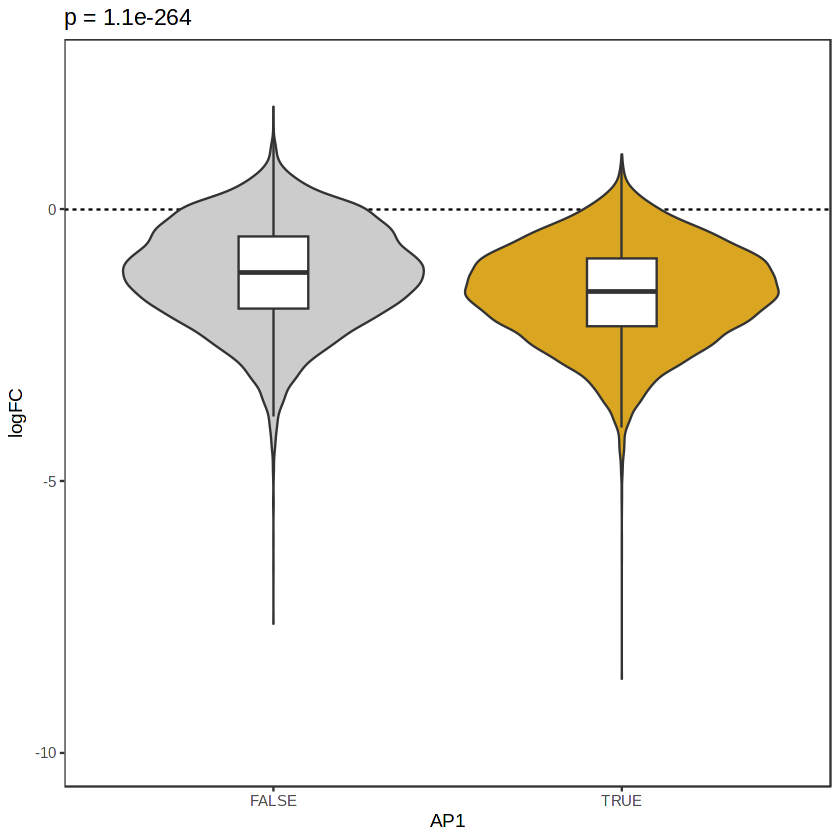

In [5]:
#plot
ggplot(DARs, aes(x=AP1, y=logFC)) + 

    geom_hline(yintercept=0, linetype=2) + 
    geom_violin(aes(fill=AP1), show.legend=FALSE) + 
    geom_boxplot(width=.2, outlier.shape=NA) +
    ggtitle(paste("p =", format(p,digits=3))) +
    scale_fill_manual(values=c("#cccccc", "goldenrod")) +
    coord_cartesian(ylim=c(-10,2.5)) + scale_y_continuous(breaks=c(-10,-5,0))
ggsave("PanelG.pdf", width=2, height=3)